# 04 — Phân Tích Các Tác Tử Học Sâu (Cấp 5, Cấp 7 & Cấp 8)

Notebook này tổng hợp toàn bộ kết quả huấn luyện và đánh giá nhóm tác tử dựa trên mạng **Dual-Head ResNet**:
1. **Cấp 5 (Supervised Dual-Head ResNet):** Đường cong Loss, Top-1 / Top-3 Policy Accuracy và Value MSE so với Zero-Baseline trên 100,355 mẫu Test độc lập.
2. **Cấp 7 (Guided MCTS - PUCT):** Kiểm thử suy luận thực tế kết hợp Policy Prior $P(s, a)$, Value Head $V(s)$, FPU Reduction, Zobrist Eval Cache và Batched Virtual Loss.
3. **Cấp 8 (AlphaZero-inspired Self-Play + Arena Gating):** Biểu đồ tỷ lệ điểm Arena (Wilson 95% CI vs ngưỡng 55%) và phân tích rào cản tính toán.

In [1]:
import json
from pathlib import Path
import sys

import chess
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from chess_ai.agents.level5_supervised import Level5SupervisedAgent
from chess_ai.agents.level7_guided_mcts import Level7GuidedMCTSAgent
from chess_ai.agents.level8_alphazero import Level8AlphaZeroAgent
from chess_ai.core.chess_env import ChessEnv

print("PROJECT_ROOT:", PROJECT_ROOT)

PROJECT_ROOT: d:\Projects\TTNTNC_local\101_chess_agent\101_TTNTNC


## 1. Cấp 5 — Kết Quả Huấn Luyện Có Giám Sát (`sl_training_metrics.json`)

,"Chỉ số (Tập Test = 100,355 mẫu)",Giá trị
0,Top-1 Policy Accuracy,34.41%
1,Top-3 Policy Accuracy,60.74%
2,Test Policy Cross-Entropy Loss,2.3617
3,Test Value MSE,0.6983
4,Zero-Baseline MSE,0.8135 (Giảm 14.2%)
5,Best Epoch / Early Stopped,Epoch 12/17 (Early stop: True)
6,Thời gian huấn luyện (GPU),1051.0s (~17.5 phút)


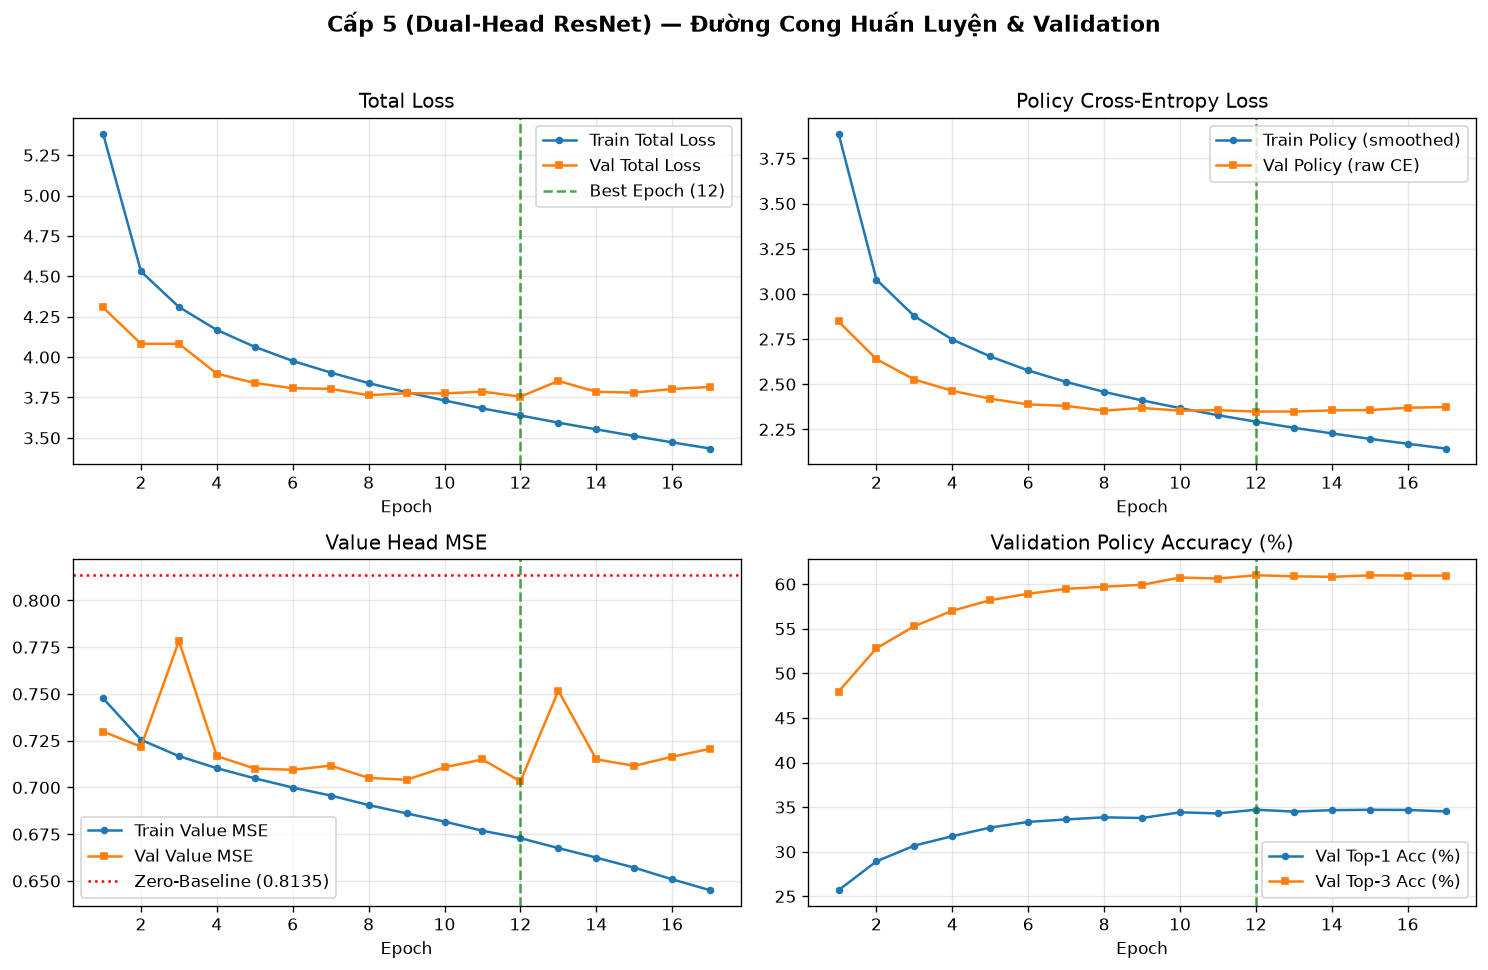

In [2]:
sl_path = PROJECT_ROOT / "results" / "training" / "sl_training_metrics.json"
sl_data = json.loads(sl_path.read_text(encoding="utf-8"))
hist = sl_data["history"]
test_ev = sl_data["test_evaluation"]

df_sl = pd.DataFrame(hist)
best_idx = int(df_sl["val_total_loss"].idxmin())
best_ep = int(df_sl.loc[best_idx, "epoch"])
zero_mse = float(test_ev["zero_baseline_mse"])

summary_l5 = pd.DataFrame([
    {"Chỉ số (Tập Test = 100,355 mẫu)": "Top-1 Policy Accuracy", "Giá trị": f"{test_ev['top1_policy_acc']*100:.2f}%"},
    {"Chỉ số (Tập Test = 100,355 mẫu)": "Top-3 Policy Accuracy", "Giá trị": f"{test_ev['top3_policy_acc']*100:.2f}%"},
    {"Chỉ số (Tập Test = 100,355 mẫu)": "Test Policy Cross-Entropy Loss", "Giá trị": f"{test_ev['policy_loss']:.4f}"},
    {"Chỉ số (Tập Test = 100,355 mẫu)": "Test Value MSE", "Giá trị": f"{test_ev['value_mse']:.4f}"},
    {"Chỉ số (Tập Test = 100,355 mẫu)": "Zero-Baseline MSE", "Giá trị": f"{zero_mse:.4f} (Giảm {(1 - test_ev['value_mse']/zero_mse)*100:.1f}%)"},
    {"Chỉ số (Tập Test = 100,355 mẫu)": "Best Epoch / Early Stopped", "Giá trị": f"Epoch {best_ep}/{sl_data['epochs_completed']} (Early stop: {sl_data.get('early_stopped')})"},
    {"Chỉ số (Tập Test = 100,355 mẫu)": "Thời gian huấn luyện (GPU)", "Giá trị": f"{sl_data['elapsed_sec']:.1f}s (~{sl_data['elapsed_sec']/60:.1f} phút)"},
])
display(summary_l5)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2), dpi=120)
fig.suptitle("Cấp 5 (Dual-Head ResNet) — Đường Cong Huấn Luyện & Validation", fontsize=13, fontweight="bold")

axes[0, 0].plot(df_sl["epoch"], df_sl["train_total_loss"], marker="o", ms=3.5, label="Train Total Loss")
axes[0, 0].plot(df_sl["epoch"], df_sl["val_total_loss"], marker="s", ms=3.5, label="Val Total Loss")
axes[0, 0].axvline(best_ep, color="green", ls="--", alpha=0.7, label=f"Best Epoch ({best_ep})")
axes[0, 0].set_title("Total Loss"); axes[0, 0].set_xlabel("Epoch"); axes[0, 0].grid(True, alpha=0.3); axes[0, 0].legend()

axes[0, 1].plot(df_sl["epoch"], df_sl["train_policy_loss"], marker="o", ms=3.5, label="Train Policy (smoothed)")
axes[0, 1].plot(df_sl["epoch"], df_sl["val_policy_loss"], marker="s", ms=3.5, label="Val Policy (raw CE)")
axes[0, 1].axvline(best_ep, color="green", ls="--", alpha=0.7)
axes[0, 1].set_title("Policy Cross-Entropy Loss"); axes[0, 1].set_xlabel("Epoch"); axes[0, 1].grid(True, alpha=0.3); axes[0, 1].legend()

axes[1, 0].plot(df_sl["epoch"], df_sl["train_value_loss"], marker="o", ms=3.5, label="Train Value MSE")
axes[1, 0].plot(df_sl["epoch"], df_sl["val_value_mse"], marker="s", ms=3.5, label="Val Value MSE")
axes[1, 0].axhline(zero_mse, color="red", ls=":", lw=1.5, label=f"Zero-Baseline ({zero_mse:.4f})")
axes[1, 0].axvline(best_ep, color="green", ls="--", alpha=0.7)
axes[1, 0].set_title("Value Head MSE"); axes[1, 0].set_xlabel("Epoch"); axes[1, 0].grid(True, alpha=0.3); axes[1, 0].legend()

axes[1, 1].plot(df_sl["epoch"], df_sl["val_top1_policy_acc"] * 100, marker="o", ms=3.5, label="Val Top-1 Acc (%)")
axes[1, 1].plot(df_sl["epoch"], df_sl["val_top3_policy_acc"] * 100, marker="s", ms=3.5, label="Val Top-3 Acc (%)")
axes[1, 1].axvline(best_ep, color="green", ls="--", alpha=0.7)
axes[1, 1].set_title("Validation Policy Accuracy (%)"); axes[1, 1].set_xlabel("Epoch"); axes[1, 1].grid(True, alpha=0.3); axes[1, 1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 2. Cấp 7 — Demo Suy Luận Guided MCTS (PUCT) vs Cấp 5 (Policy-Only)

In [3]:
ckpt_l5 = str(PROJECT_ROOT / "checkpoints" / "best_model.pt")
ckpt_l8 = str(PROJECT_ROOT / "checkpoints" / "l8_alphazero_best.pt")

ag5 = Level5SupervisedAgent(checkpoint_path=ckpt_l5, allow_untrained_fallback=False)
ag7 = Level7GuidedMCTSAgent(checkpoint_path=ckpt_l5, simulations=200, eval_mode=True, allow_untrained_fallback=False)
ag8 = Level8AlphaZeroAgent(checkpoint_path=ckpt_l8, simulations=200, eval_mode=True, allow_untrained_fallback=False)

probe_positions = {
    "Khai cuộc chuẩn": chess.STARTING_FEN,
    "Trung cuộc Italian": "r1bqkbnr/pppp1ppp/2n5/4p3/2B1P3/5N2/PPPP1PPP/RNBQK2R w KQkq - 4 4",
}
rows = []
for pname, fen in probe_positions.items():
    for ag, wl in ((ag5, None), (ag7, 200), (ag8, 200)):
        ag.reset()
        env = ChessEnv(fen=fen)
        mv = ag.select_move(env, max_workload=wl)
        st = ag.last_search_stats
        rows.append({
            "Thế cờ": pname,
            "Tác tử": ag.name,
            "Nước chọn": env.board.san(mv),
            "Eval": round(float(st.get("eval", 0.0)), 4),
            "Sims": int(st.get("simulations", 0)),
            "Cache Hits": int(st.get("cache_hits", 0)),
            "Độ trễ (ms)": round(float(st.get("time_sec", 0.0)) * 1000.0, 1),
        })
display(pd.DataFrame(rows))

,Thế cờ,Tác tử,Nước chọn,Eval,Sims,Cache Hits,Độ trễ (ms)
0,Khai cuộc chuẩn,Level5_Supervised,e3,-0.0390,0,0,175.9
1,Khai cuộc chuẩn,Level7_GuidedMCTS,e3,0.0121,200,24,153.6
2,Khai cuộc chuẩn,Level8_AlphaZero,e3,0.0121,200,24,94.1
3,Trung cuộc Italian,Level5_Supervised,d4,-0.0137,0,0,2.4
4,Trung cuộc Italian,Level7_GuidedMCTS,d4,0.0151,200,16,113.1
5,Trung cuộc Italian,Level8_AlphaZero,d4,0.0151,200,16,109.3


## 3. Cấp 8 — Kết Quả Vòng Lặp Self-Play & Checkpoint Arena Gating (`selfplay_metrics.json`)

,Iter,Self-Play Games,Buffer,Policy Loss,Value Loss,Arena Score (%),W/D/L,Wilson 95% CI,Accepted,Time (s)
0,1,20,2217,2.45884,0.30897,45.0,6/6/8,"[25.8%, 65.8%]",False,341.21
1,2,20,4217,2.49613,0.34507,50.0,9/2/9,"[29.9%, 70.1%]",False,304.93
2,3,20,6389,2.46819,0.36920,37.5,5/5/10,"[20.0%, 59.1%]",False,296.28
3,4,20,8437,2.48406,0.38852,35.0,6/2/12,"[18.1%, 56.7%]",False,305.24
4,5,20,10605,2.49741,0.46957,50.0,8/4/8,"[29.9%, 70.1%]",False,338.42
5,6,20,12534,2.48397,0.46350,42.5,6/5/9,"[23.8%, 63.6%]",False,336.46


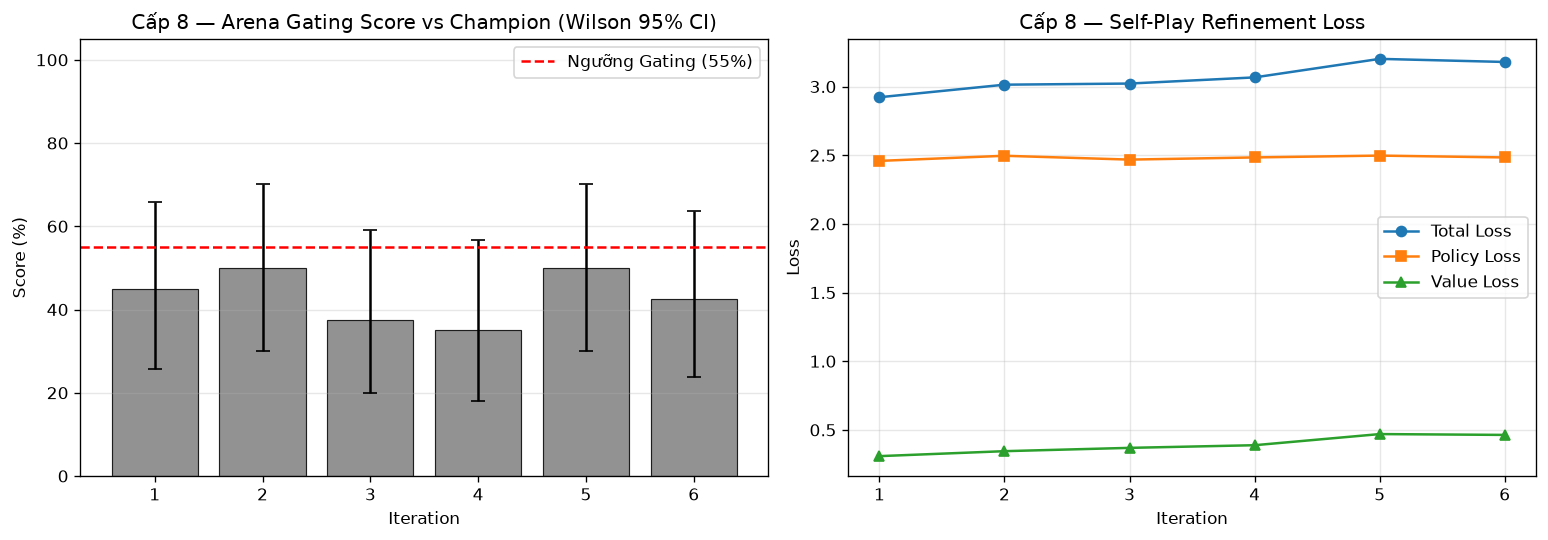

In [4]:
sp_path = PROJECT_ROOT / "results" / "training" / "selfplay_metrics.json"
sp = json.loads(sp_path.read_text(encoding="utf-8"))
sp_hist = sp["history"]

df_sp = pd.DataFrame([
    {
        "Iter": h["iteration"],
        "Self-Play Games": h["selfplay_games"],
        "Buffer": h["buffer_size"],
        "Policy Loss": h["train_policy_loss"],
        "Value Loss": h["train_value_loss"],
        "Arena Score (%)": round(h["arena"]["score_rate"] * 100.0, 1),
        "W/D/L": f"{h['arena']['wins']}/{h['arena']['draws']}/{h['arena']['losses']}",
        "Wilson 95% CI": f"[{h['arena'].get('wilson_ci_95', [0,0])[0]*100:.1f}%, {h['arena'].get('wilson_ci_95', [0,0])[1]*100:.1f}%]",
        "Accepted": h["arena"]["accepted"],
        "Time (s)": h["elapsed_sec"],
    }
    for h in sp_hist
])
display(df_sp)

iters = df_sp["Iter"].tolist()
scores = df_sp["Arena Score (%)"].tolist()
cis = [h["arena"].get("wilson_ci_95", [h["arena"]["score_rate"], h["arena"]["score_rate"]]) for h in sp_hist]
err_low = [max(0.0, s - ci[0] * 100.0) for s, ci in zip(scores, cis)]
err_high = [max(0.0, ci[1] * 100.0 - s) for s, ci in zip(scores, cis)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), dpi=120)
colors = ["#2ca02c" if h["arena"]["accepted"] else "#7f7f7f" for h in sp_hist]
ax1.bar(iters, scores, color=colors, alpha=0.85, edgecolor="black", lw=0.7)
ax1.errorbar(iters, scores, yerr=[err_low, err_high], fmt="none", ecolor="black", capsize=4)
ax1.axhline(55.0, color="red", ls="--", lw=1.5, label="Ngưỡng Gating (55%)")
ax1.set_title("Cấp 8 — Arena Gating Score vs Champion (Wilson 95% CI)")
ax1.set_xlabel("Iteration"); ax1.set_ylabel("Score (%)"); ax1.set_ylim(0, 105); ax1.grid(True, axis="y", alpha=0.3); ax1.legend()

ax2.plot(iters, [h["train_total_loss"] for h in sp_hist], marker="o", label="Total Loss")
ax2.plot(iters, [h["train_policy_loss"] for h in sp_hist], marker="s", label="Policy Loss")
ax2.plot(iters, [h["train_value_loss"] for h in sp_hist], marker="^", label="Value Loss")
ax2.set_title("Cấp 8 — Self-Play Refinement Loss")
ax2.set_xlabel("Iteration"); ax2.set_ylabel("Loss"); ax2.grid(True, alpha=0.3); ax2.legend()

plt.tight_layout()
plt.show()

### Nhận xét về Cơ chế Arena Gating & Bảo toàn `Champion v0`

- Trong 6 vòng Self-Play (`20 ván/vòng`, `100 sims/nước`, tổng `12.534 mẫu`), các bản Challenger đạt `35.0% – 50.0%` trước Champion (dưới ngưỡng `55%`), nên **Arena Gating đã từ chối cả 6 bản và giữ nguyên `Champion v0`** (trọng số `l8_alphazero_best.pt` trùng với `best_model.pt` của Level 5).
- **Nguyên nhân:** Mạng warm-start Level 5 đã được huấn luyện trên **1.000.000 mẫu Lichess Elite (ELO ~2580)**, có chất lượng vượt trội so với dữ liệu tự chơi ngân sách nhỏ (`100 sims/nước`). Kết quả này chứng minh cổng kiểm duyệt hoạt động đúng mục tiêu **chống suy thoái mô hình (*anti-regression*)**. Chi tiết hướng nâng cấp tương lai xem tại `docs/LEVEL8_SELFPLAY_LIMITATIONS_AND_FUTURE.md`.